In [1]:
TSN = 200157867
d = 67
alpha = 2
s = 8
h_bar, m, omega = 1, 1, 1

In [2]:
x_start = ((-1)**s)*(0.5+67/200)
print(x_start)

0.835


Problem A

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animate
from pathlib import Path
from matplotlib.lines import Line2D


In [4]:
K_eps = np.zeros((601, 601), dtype = np.complex128);

def propagatorK (m, omega, h_bar, x_a, x_b, deltaT): #function for a single propagator
    C = np.sqrt((m * omega)/
         (2 * np.pi * 1j * h_bar * np.sin(omega*deltaT)))
    
    exp = (1j * m * omega)/(2 * h_bar * np.sin(omega * (deltaT))) * ((x_a ** 2 + x_b ** 2) * np.cos(omega*(deltaT))- 2 * x_a * x_b)
    
    K = C * np.e ** exp
    return K
    
epsilon = 2 * np.pi/128;
deltax = 8/600;

for i in range(601):
    for k in range(601):
        x_a = -4 + i * deltax
        x_b = -4 + k * deltax
        
        K_eps[k, i] = propagatorK (1, 1, 1, x_a, x_b, epsilon)
                
K_8eps = deltax ** 7 * np.linalg.matrix_power(K_eps, 8)
print(K_8eps)
     

[[-0.05955846+0.0178667j  -0.0757611 +0.0217024j  -0.07967385+0.05414053j
  ... -0.46505982-0.30932634j -0.35439299-0.42735575j
  -0.21687407-0.50917202j]
 [-0.0757611 +0.0217024j  -0.0896081 +0.03330227j -0.08308486+0.06724787j
  ... -0.53404108-0.16837676j -0.46141968-0.31131639j
  -0.35439299-0.42735575j]
 [-0.07967385+0.05414053j -0.08308486+0.06724787j -0.06226964+0.09303051j
  ... -0.56407376-0.01040964j -0.53404108-0.16837676j
  -0.46505982-0.30932634j]
 ...
 [-0.46505982-0.30932634j -0.53404108-0.16837676j -0.56407376-0.01040964j
  ... -0.06226964+0.09303051j -0.08308486+0.06724787j
  -0.07967385+0.05414053j]
 [-0.35439299-0.42735575j -0.46141968-0.31131639j -0.53404108-0.16837676j
  ... -0.08308486+0.06724787j -0.0896081 +0.03330227j
  -0.0757611 +0.0217024j ]
 [-0.21687407-0.50917202j -0.35439299-0.42735575j -0.46505982-0.30932634j
  ... -0.07967385+0.05414053j -0.0757611 +0.0217024j
  -0.05955846+0.0178667j ]]


Problem B

In [5]:
def phi0 (x): #define wave-function of the electrons)
    C = (2 / np.pi) ** (1/4)
    exp = -1 * (x - x_start) ** 2
    phi0 = C * np.e ** exp
    return phi0

#find the initial wavefunction at each electron location 
#and record each electron location

iniamp = np.zeros((601), dtype=np.complex128)
x_pos = np.zeros((601), dtype=np.complex128)
for i in range (601):
    x_e = -4 + i * deltax
    iniamp[i] = phi0(x_e)
    x_pos[i] = x_e

In [6]:
#initialize needed arrays for plotting 
time = np.linspace(0, 2 * np.pi, 129)
ntamp = iniamp.copy()
x_exp = np.zeros((129), dtype = np.float64)

In [7]:
#graph, evolve wavefunction one time step per loop

for n in range (129):
    #at t=n+1 timestep, expected value of x
    x_exp[n] = sum(deltax * x_pos * (np.abs(ntamp) ** 2))

    #propagated wavefunction by one timestep
    ntamp = deltax * K_eps @ ntamp 

/tmp/ipykernel_1989/2544229925.py:5: ComplexWarning: Casting complex values to real discards the imaginary part
  x_exp[n] = sum(deltax * x_pos * (np.abs(ntamp) ** 2))


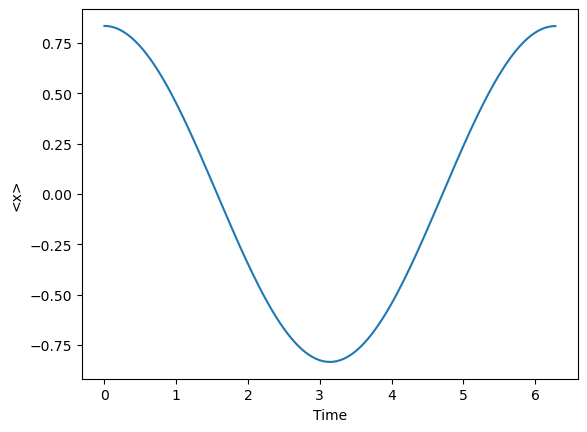

In [8]:
plt.plot(time, x_exp)
plt.xlabel("Time")
plt.ylabel("<x>")
plt.show()

Problem C

In [9]:
#initialize needed arrays for plotting 
ntamp = iniamp.copy()
V = np.zeros((129), dtype = np.float64)
K = V.copy()
E = V.copy()

In [10]:
for n in range (129):

    #Potential 
    V[n] = sum(0.5 * deltax * (x_pos ** 2) * (np.abs(ntamp) ** 2))

    #Kinetic
    #Approximate the derivative of the propagated wavefunction 
    #at x_i by taking the slope between two points (x_i+1, x_i-1)
    der = np.gradient(ntamp, deltax)
    K[n] = h_bar ** 2 / 2 * sum(deltax * np.abs(der) ** 2)

    #Total energy
    E[n] = V[n] + K[n]

    #propagated wavefunction by one timestep
    ntamp = deltax * K_eps @ ntamp   

/tmp/ipykernel_1989/2802193848.py:4: ComplexWarning: Casting complex values to real discards the imaginary part
  V[n] = sum(0.5 * deltax * (x_pos ** 2) * (np.abs(ntamp) ** 2))


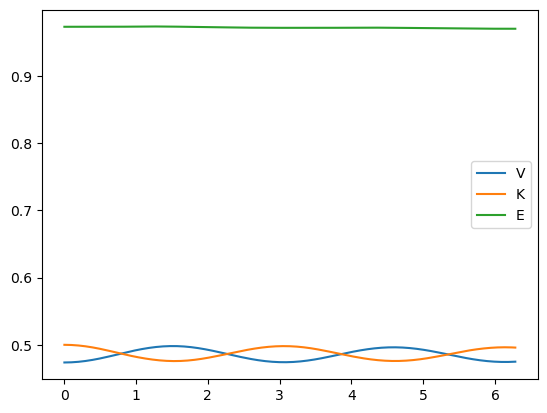

In [11]:
plt.plot(time, V, label = 'V')
plt.plot(time, K, label = 'K')
plt.plot(time, E, label = 'E')
plt.legend()

Problem D

In [12]:
#prepare another initial probability density array for calculation
mtamp = iniamp.copy()
inidense = np.abs(iniamp) ** 2
mtdense = inidense.copy()     

/opt/conda/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/conda/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


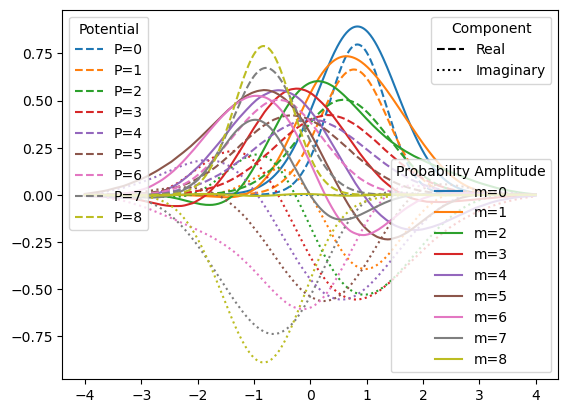

In [13]:
colors = plt.cm.tab10.colors
P_t_lines = []
mtampreal_lines = []
P_list = []

for m in range(9):

    color = colors[m % len(colors)]

    P_list.append(mtdense.copy())

    #P_t(x)
    P_t, = plt.plot(x_pos, mtdense, label=f"P={m}", linestyle='--')
    #time evolution of probability amplitude
    mtampreal, = plt.plot(x_pos, mtamp.real, color=color, label=f"m={m}")
    mtampimag = plt.plot(x_pos, mtamp.imag, color=color, linestyle=':')
    
    mtamp = deltax * K_8eps @ mtamp
    mtdense = np.abs(mtamp) ** 2

    P_t_lines.append(P_t)
    mtampreal_lines.append(mtampreal)

legend1 = plt.legend(
    handles=P_t_lines,
    title="Potential",
    loc="upper left"
)

plt.gca().add_artist(legend1)

legend2 = plt.legend(
    handles=mtampreal_lines,
    title="Probability Amplitude - Real",
    loc="lower right"
)

style_lines = [
    Line2D([0], [0], color="black", linestyle="--", label="Real"),
    Line2D([0], [0], color="black", linestyle=":", label="Imaginary")
]

style_legend = plt.legend(
    handles=style_lines,
    title="Component",
    loc="upper right"
)

plt.gca().add_artist(style_legend)

color_legend = plt.legend(
    handles=mtampreal_lines,
    title="Probability Amplitude",
    loc="lower right"
)

Problem E

In [14]:
animateamp = iniamp.copy()

Saved: /home/kaye/phys142_kye/assignments/HO.gif with 129 frames


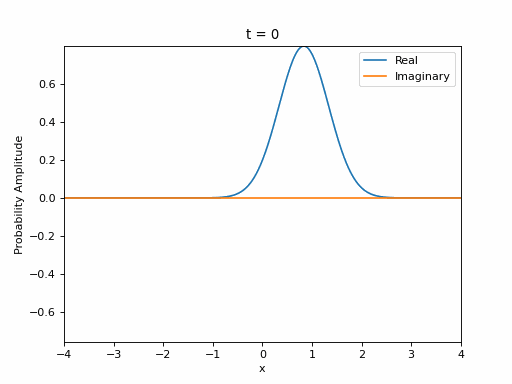

In [15]:
# start from the initial probability amplitude
animateamp = inidense.copy()

animateamp_list = [animateamp.copy()]

for n in range(128):
    animateamp = deltax * K_eps @ animateamp
    animateamp_list.append(animateamp.copy())

fig, ax = plt.subplots()

line_real, = ax.plot(x_pos, animateamp_list[0].real, label="Real")

line_imag, = ax.plot(x_pos, animateamp_list[0].imag, label="Imaginary")

ax.set_xlim(-4, 4)

# fixed vertical range for all frames
y_min = min(min(np.min(amp.real), np.min(amp.imag)) for amp in animateamp_list)

y_max = max(max(np.max(amp.real), np.max(amp.imag)) for amp in animateamp_list)

ax.set_ylim(y_min, y_max)

ax.set_xlabel("x")
ax.set_ylabel("Probability Amplitude")
ax.legend()


# function called for each animation frame
def time_evolution(frame):

    line_real.set_ydata(animateamp_list[frame].real)

    line_imag.set_ydata(animateamp_list[frame].imag)

    ax.set_title(f"t = {frame}")

    return line_real, line_imag

# create animation
from IPython.display import Image, display
plot = animate.FuncAnimation(fig, time_evolution, frames=129, interval=50)
gif_path = Path("HO.gif")
plot.save(gif_path, writer="pillow", dpi=80)
plt.close(fig)
print("Saved:", gif_path.resolve(), "with", len(animateamp_list), "frames")
display(Image(filename=str(gif_path)))

Problem F

The second case will fail because the time steps are too small.

When the grid size is fixed, the smaller the time step, the more rapidly the propagator will oscillate; when the size of the time step is fixed, the greater the grid size, the more rapidly the propagator will oscillate.

For $N_D$ = 600, the smallest time step that works must be between 128 and 512, I would predict that it will be near 200, if $N_D$ doubles, then we will need to decrease the timestep by the same proportion

i)

In [16]:
iniamp = np.zeros((601), dtype=np.complex128)
x_pos = np.zeros((601), dtype=np.complex128)

In [17]:
epsilon = 2 * np.pi/16;
deltax = 8/600;

#propagator
for i in range(601):
    for k in range(601):
        x_a = -4 + i * deltax
        x_b = -4 + k * deltax
        
        K_eps[k, i] = propagatorK (1, 1, 1, x_a, x_b, epsilon)

#initial wavefunction
for i in range (601):
    x_e = -4 + i * deltax
    iniamp[i] = phi0(x_e)
    x_pos[i] = x_e

oneamp = iniamp.copy()

oneN = np.zeros(17)
onetime = np.zeros(17)

for n in range(17):

    oneN[n] = deltax * np.sum(np.abs(oneamp) ** 2)
    onetime[n] = n * epsilon
    oneamp = deltax * K_eps @ oneamp

ii)

In [18]:
x_pos = np.zeros((601), dtype=np.complex128)

In [19]:
epsilon = 2 * np.pi/512;
deltax = 8/600;

#propagator
for i in range(601):
    for k in range(601):
        x_a = -4 + i * deltax
        x_b = -4 + k * deltax
        
        K_eps[k, i] = propagatorK (1, 1, 1, x_a, x_b, epsilon)

#initial wavefunction
for i in range (601):
    x_e = -4 + i * deltax
    iniamp[i] = phi0(x_e)
    x_pos[i] = x_e

twoamp = iniamp.copy()

twoN = np.zeros(513)
twotime = np.zeros(513)

for n in range(513):

    twoN[n] = deltax * np.sum(np.abs(twoamp) ** 2)
    twotime[n] = n * epsilon
    twoamp = deltax * K_eps @ twoamp

iii)

In [20]:
x_pos = np.zeros((151), dtype=np.complex128)

In [21]:
epsilon = 2 * np.pi/128;
deltax = 8/150;

#propagator
for i in range(151):
    for k in range(151):
        x_a = -4 + i * deltax
        x_b = -4 + k * deltax
        
        K_eps[k, i] = propagatorK (1, 1, 1, x_a, x_b, epsilon)

#initial wavefunction
for i in range (151):
    x_e = -4 + i * deltax
    iniamp[i] = phi0(x_e)
    x_pos[i] = x_e
    
threeamp = iniamp.copy()

threeN = np.zeros(129)
threetime = np.zeros(129)

for n in range(129):

    threeN[n] = deltax * np.sum(np.abs(threeamp) ** 2)
    threetime[n] = n * epsilon
    threeamp = deltax * K_eps @ threeamp

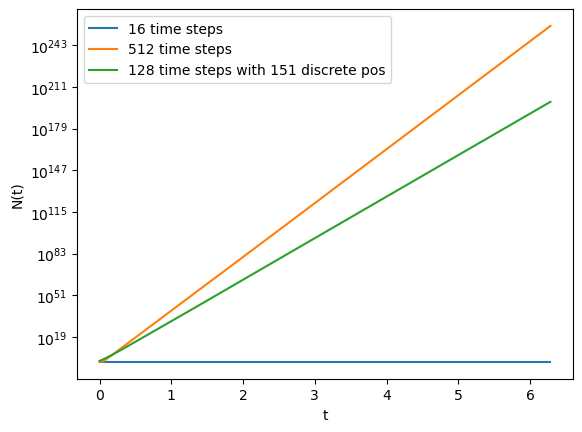

In [22]:
#plot
plt.plot(onetime, oneN, label='16 time steps')

plt.plot(twotime, twoN, label='512 time steps')

plt.plot(threetime, threeN, label='128 time steps with 151 discrete pos')
         
plt.yscale('log')
plt.xlabel('t')
plt.ylabel('N(t)')
plt.legend()

Output file

In [23]:
import json

results = {
    "tsn": "200157867",
    "x_start": x_start,
    "K8eps_row": {"re": K_8eps[300].real.tolist() ,
                  "im": K_8eps[300].imag.tolist() },
    "x_mean": x_exp.tolist(),
    "V": V.tolist(), "K": K.tolist(), "E": E.tolist(),
    "P": [P_t.tolist() for P_t in P_list],
}
with open("result.json", "w") as f:
    json.dump(results, f)

Appendix:

Used AI: ChatGPT
Used For: Checking code accuracy, debugging errors in the code, and formatting plots. Also used for asking for something I don't know how to code. Prompts include sending snippets of the code for it to see, asking it to see if there is anything wrong, missing, or can be written more efficiently; giving it an error output and ask it to diagnose what's wrong; asking it how to format the plot. 

